<img src="https://reqlut2.s3.amazonaws.com/uploads/alumni/0fef69ec3960b87bc64851d6ce15ebe309117cf6-javeriana.png" width="200"/>

# PONTIFICIA UNIVERSIDAD JAVERIANA
## Clase Procesamiento de datos a Gran Escala

**Fecha:** 02/10/2026  
**Autor:** Juan David Manosalva Duarte, Juan David Murcia, Sergio Clavijo, Juan Diego Soler, Isabella Achury  
**Profesor:** John Corredor  
**Tema:** Entrega 1 Proyecto (base SAT 2012 por colegio)

**Objetivos:**

- Aplicar la metodología CRISP DM en datasets de las ciencias de la salud
- Documentar de forma exhaustiva cada actividad realizada de la metodología
- Crear y analizar gráficas: comprender la creación de gráficas como imágenes que documenten de forma académica
- Hacer las recomendaciones, conclusiones y análisis correspondientes

In [1]:
#Generic Libraries
import findspark
findspark.init()
import numpy as np                         # linear algebra
import pandas as pd                        # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns                      # Creación de gráficas y biblioteca estadística
import matplotlib.pyplot as plt            # Implementación de gráficos

#Apache Spark Libraries
import pyspark
from pyspark import SparkConf, SparkContext             # SparConf:               //SparkContext:
from pyspark.sql import SparkSession, SQLContext

#Apache Spark ML CLassifier Libraries
from pyspark.ml.classification import DecisionTreeClassifier,RandomForestClassifier,NaiveBayes

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Apache Spark Pipelin Library
from pyspark.ml import Pipeline

# Apache Spark `DenseVector`
from pyspark.ml.linalg import DenseVector  #Para poner los datos en un vector compuesto

#Data Split Libraries
import sklearn                             #Modelos de ML
from sklearn.model_selection import train_test_split

In [2]:
#Se crea una configuración para la sesión SPARK
#Se configura
configura = SparkConf()
configura.setAppName("SparkBigDataProyecto")
#Se crea el contexto para la sesión
sparkProyecto = SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=sparkProyecto.sparkContext, sparkSession=sparkProyecto)
#Se levanta el contexto para la sesión: Aplicación de Derrame Cerebral en SPARK
sparkContextProyecto = sparkProyecto.sparkContext.getOrCreate()
#Se imprime para verificar
print("Sesión creada el 24 sep 2026")
sparkProyecto

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/02 23:04:53 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Sesión creada el 24 sep 2026


 ## Como cada miembro del cluster lo nombró distinto, lo que se hizo fue leer el de acá y pasarlo al cluster

In [3]:
import pandas as pd

archivoSAT = pd.read_csv("2012_SAT_Results_20261002.csv")
df00 = sparkProyecto.createDataFrame(archivoSAT)

df00.show(5)

+------+--------------------+----------------------+-------------------------------+-------------------+----------------------+
|   DBN|         SCHOOL NAME|Num of SAT Test Takers|SAT Critical Reading Avg. Score|SAT Math Avg. Score|SAT Writing Avg. Score|
+------+--------------------+----------------------+-------------------------------+-------------------+----------------------+
|01M292|HENRY STREET SCHO...|                    29|                            355|                404|                   363|
|01M448|UNIVERSITY NEIGHB...|                    91|                            383|                423|                   366|
|01M450|EAST SIDE COMMUNI...|                    70|                            377|                402|                   370|
|01M458|FORSYTH SATELLITE...|                     7|                            414|                401|                   359|
|01M509|MARTA VALLE HIGH ...|                    44|                            390|                433|

## cantidad de individuos en la BD

In [4]:
df00.count()

26/10/02 23:06:08 WARN TaskSchedulerImpl: Initial job has not accepted any resources; check your cluster UI to ensure that workers are registered and have sufficient resources
                                                                                

478

## Los disntintos tipos de datos y nombres de los parametros

In [5]:
df00.printSchema()

root
 |-- DBN: string (nullable = true)
 |-- SCHOOL NAME: string (nullable = true)
 |-- Num of SAT Test Takers: string (nullable = true)
 |-- SAT Critical Reading Avg. Score: string (nullable = true)
 |-- SAT Math Avg. Score: string (nullable = true)
 |-- SAT Writing Avg. Score: string (nullable = true)



## agrupamos los colegios por distrito escolar (los dos primeros caracteres del DBN) en orden ascendente

In [6]:
from pyspark.sql import functions as F

df00.groupBy(F.substring("DBN", 1, 2).alias("DISTRITO_ESCOLAR")).count().orderBy("DISTRITO_ESCOLAR").show(40)

+----------------+-----+
|DISTRITO_ESCOLAR|count|
+----------------+-----+
|              01|    9|
|              02|   65|
|              03|   17|
|              04|    7|
|              05|   10|
|              06|   11|
|              07|   17|
|              08|   21|
|              09|   22|
|              10|   28|
|              11|   19|
|              12|   18|
|              13|   18|
|              14|   16|
|              15|   13|
|              16|    5|
|              17|   20|
|              18|   14|
|              19|   14|
|              20|    6|
|              21|   13|
|              22|    5|
|              23|    6|
|              24|   15|
|              25|   11|
|              26|    5|
|              27|   11|
|              28|   14|
|              29|   10|
|              30|    9|
|              31|   12|
|              32|    7|
|              75|    7|
|              79|    3|
+----------------+-----+



## eliminamos variables que no tengan utilidad en la investigacion

En esta base las 6 variables sirven (el DBN dice dónde está el colegio, el nombre sirve para identificarlo y las otras cuatro son el resultado de la prueba), así que no se elimina ninguna.

In [7]:
# no se elimina ninguna variable
df01 = df00

## cambiamos el nombre de las variables para mayor legibilidad

In [9]:
nuevosNombres = [
    'Dbn',           # Reemplaza a DBN
    'Colegio',       # Reemplaza a SCHOOL NAME
    'Examinados',    # Reemplaza a Num of SAT Test Takers
    'Lectura',       # Reemplaza a SAT Critical Reading Avg. Score
    'Matematicas',   # Reemplaza a SAT Math Avg. Score
    'Escritura'      # Reemplaza a SAT Writing Avg. Score
]

# 3. Aplicamos el cambio de nombre
df02 = df01
for antes, nuevo in zip(df01.columns, nuevosNombres):
    df02 = df02.withColumnRenamed(antes, nuevo)

# 4. Comprobamos la estructura y los primeros datos
df02.printSchema()

root
 |-- Dbn: string (nullable = true)
 |-- Colegio: string (nullable = true)
 |-- Examinados: string (nullable = true)
 |-- Lectura: string (nullable = true)
 |-- Matematicas: string (nullable = true)
 |-- Escritura: string (nullable = true)



## creamos el distrito (borough) a partir del Dbn

En esta base no hay una columna de distrito: está escondido en el `Dbn`. En el código `01M292`, la letra de la **tercera posición** es el distrito (`M` = Manhattan). Ojo: esta base usa `X` para el Bronx y `R` para Staten Island, mientras que la base de arrestos usa `B` y `S`. Por eso aquí se pasa directamente al nombre del distrito, para que después se puedan cruzar las dos bases sin confundirse.

In [10]:
from pyspark.sql import functions as F

mapa_distrito = {"X": "Bronx", "K": "Brooklyn", "M": "Manhattan", "Q": "Queens", "R": "Staten Island"}
mapa = F.create_map(*[F.lit(x) for par in mapa_distrito.items() for x in par])

df02 = df02.withColumn("Distrito", F.try_element_at(mapa, F.substring("Dbn", 3, 1)))
print("Colegios sin distrito:", df02.filter(F.col("Distrito").isNull()).count())
df02.printSchema()

Colegios sin distrito: 0
root
 |-- Dbn: string (nullable = true)
 |-- Colegio: string (nullable = true)
 |-- Examinados: string (nullable = true)
 |-- Lectura: string (nullable = true)
 |-- Matematicas: string (nullable = true)
 |-- Escritura: string (nullable = true)
 |-- Distrito: string (nullable = true)



In [11]:
df02.show()

+------+--------------------+----------+-------+-----------+---------+---------+
|   Dbn|             Colegio|Examinados|Lectura|Matematicas|Escritura| Distrito|
+------+--------------------+----------+-------+-----------+---------+---------+
|01M292|HENRY STREET SCHO...|        29|    355|        404|      363|Manhattan|
|01M448|UNIVERSITY NEIGHB...|        91|    383|        423|      366|Manhattan|
|01M450|EAST SIDE COMMUNI...|        70|    377|        402|      370|Manhattan|
|01M458|FORSYTH SATELLITE...|         7|    414|        401|      359|Manhattan|
|01M509|MARTA VALLE HIGH ...|        44|    390|        433|      384|Manhattan|
|01M515|LOWER EAST SIDE P...|       112|    332|        557|      316|Manhattan|
|01M539|NEW EXPLORATIONS ...|       159|    522|        574|      525|Manhattan|
|01M650|CASCADES HIGH SCHOOL|        18|    417|        418|      411|Manhattan|
|01M696|BARD HIGH SCHOOL ...|       130|    624|        604|      628|Manhattan|
|02M047|47 THE AMERICAN S...

## muestra los datos con los que trabajaremos

In [12]:
df02.printSchema()

root
 |-- Dbn: string (nullable = true)
 |-- Colegio: string (nullable = true)
 |-- Examinados: string (nullable = true)
 |-- Lectura: string (nullable = true)
 |-- Matematicas: string (nullable = true)
 |-- Escritura: string (nullable = true)
 |-- Distrito: string (nullable = true)



In [13]:
 !pip install matplotlib

In [14]:
df02.describe().show()

26/10/02 23:07:25 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
[Stage 10:>                                                         (0 + 1) / 1]

+-------+------+--------------------+-----------------+-----------------+-----------------+------------------+-------------+
|summary|   Dbn|             Colegio|       Examinados|          Lectura|      Matematicas|         Escritura|     Distrito|
+-------+------+--------------------+-----------------+-----------------+-----------------+------------------+-------------+
|  count|   478|                 478|              478|              478|              478|               478|          478|
|   mean|  NULL|                NULL|110.3206650831354|400.8503562945368|413.3681710213777| 393.9857482185273|         NULL|
| stddev|  NULL|                NULL|155.5342536933185|56.80278272120786|64.68465508566646|58.635108824656534|         NULL|
|    min|01M292|47 THE AMERICAN S...|               10|              279|              312|               286|        Bronx|
|    max|79X490|YOUNG WOMEN'S LEA...|                s|                s|                s|                 s|Staten Island|


## cambiamos el tipo de dato de variables (casteo)

In [15]:
### Dbn y Colegio: se castean a texto (string es el equivalente a char en PySpark)
df03 = df02.withColumn("Dbn", df02.Dbn.cast("string"))
df03 = df03.withColumn("Colegio", df03.Colegio.cast("string"))

### Examinados y los tres puntajes: se castean a entero (int)
### Ojo: algunos colegios tienen la letra "s" (valor suprimido) en lugar de un número.
### cast("int") da error con una letra, así que solo se convierte lo que son dígitos y la "s" queda como vacío (null)
for c in ["Examinados", "Lectura", "Matematicas", "Escritura"]:
    con_s = df03.filter(F.upper(F.trim(F.col(c))) == "S").count()
    df03 = df03.withColumn(c, F.when(F.trim(F.col(c)).rlike("^[0-9]+$"), F.trim(F.col(c)).cast("int")))
    vacios = df03.filter(F.col(c).isNull()).count()
    print(f"{c}: valores 's' = {con_s} | vacíos después del casteo = {vacios}")

df03.printSchema()

# Ahora que son números, el resumen sí muestra el mínimo y el máximo reales
df03.describe().show()

Examinados: valores 's' = 57 | vacíos después del casteo = 57
Lectura: valores 's' = 57 | vacíos después del casteo = 57
Matematicas: valores 's' = 57 | vacíos después del casteo = 57
Escritura: valores 's' = 57 | vacíos después del casteo = 57
root
 |-- Dbn: string (nullable = true)
 |-- Colegio: string (nullable = true)
 |-- Examinados: integer (nullable = true)
 |-- Lectura: integer (nullable = true)
 |-- Matematicas: integer (nullable = true)
 |-- Escritura: integer (nullable = true)
 |-- Distrito: string (nullable = true)



[Stage 37:>                                                         (0 + 1) / 1]

+-------+------+--------------------+-----------------+-----------------+-----------------+------------------+-------------+
|summary|   Dbn|             Colegio|       Examinados|          Lectura|      Matematicas|         Escritura|     Distrito|
+-------+------+--------------------+-----------------+-----------------+-----------------+------------------+-------------+
|  count|   478|                 478|              421|              421|              421|               421|          478|
|   mean|  NULL|                NULL|110.3206650831354|400.8503562945368|413.3681710213777| 393.9857482185273|         NULL|
| stddev|  NULL|                NULL|155.5342536933185|56.80278272120786|64.68465508566646|58.635108824656534|         NULL|
|    min|01M292|47 THE AMERICAN S...|                6|              279|              312|               286|        Bronx|
|    max|79X490|YOUNG WOMEN'S LEA...|             1277|              679|              735|               682|Staten Island|


## graficas

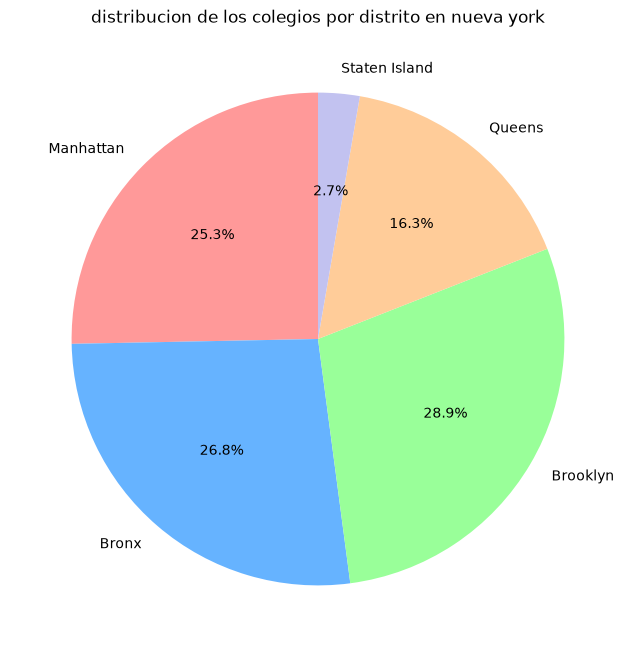

In [16]:
import matplotlib.pyplot as plt


colegios_por_distrito = df03.groupBy("Distrito").count()


pd_distrito = colegios_por_distrito.toPandas()


plt.figure(figsize=(8, 8)) 
plt.pie(
    pd_distrito['count'],              
    labels=pd_distrito['Distrito'],   
    autopct='%1.1f%%',              
    startangle=90,               
    colors=['#ff9999','#66b3ff','#99ff99','#ffcc99', '#c2c2f0'] 
)


plt.title('distribucion de los colegios por distrito en nueva york')
plt.show()

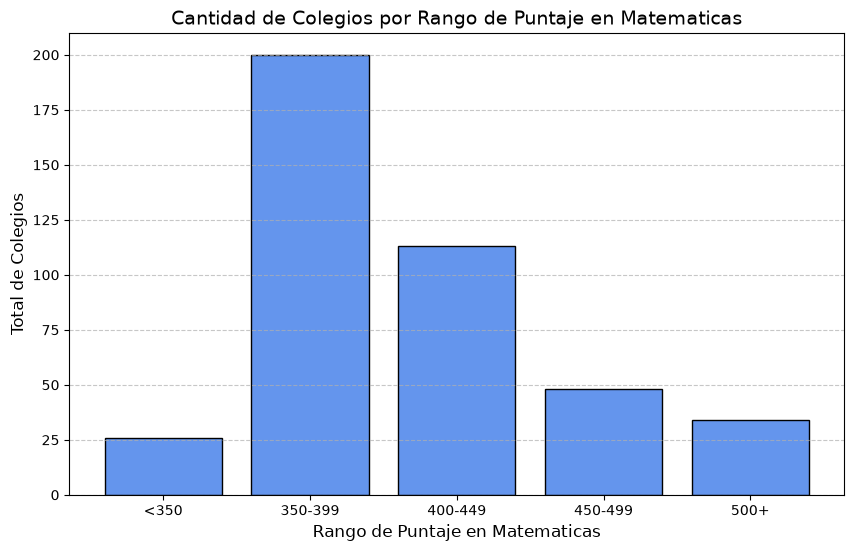

In [17]:
import matplotlib.pyplot as plt

# Los colegios se agrupan por rango de puntaje en matematicas (los que tienen "s" no se cuentan porque no tienen puntaje)
rango_matematicas = (F.when(F.col("Matematicas") < 350, "<350")
                      .when(F.col("Matematicas") < 400, "350-399")
                      .when(F.col("Matematicas") < 450, "400-449")
                      .when(F.col("Matematicas") < 500, "450-499")
                      .otherwise("500+"))
dfRangos = df03.filter(F.col("Matematicas").isNotNull()).withColumn("RangoMatematicas", rango_matematicas)

rangos_spark = dfRangos.groupBy("RangoMatematicas").count()

pd_rangos = rangos_spark.toPandas()

orden_rangos = ['<350', '350-399', '400-449', '450-499', '500+']
pd_rangos['RangoMatematicas'] = pd.Categorical(pd_rangos['RangoMatematicas'], categories=orden_rangos, ordered=True)
pd_rangos = pd_rangos.sort_values(by='RangoMatematicas')

plt.figure(figsize=(10, 6))

plt.bar(pd_rangos['RangoMatematicas'].astype(str), pd_rangos['count'], color='cornflowerblue', edgecolor='black')

plt.title('Cantidad de Colegios por Rango de Puntaje en Matematicas', fontsize=14)
plt.xlabel('Rango de Puntaje en Matematicas', fontsize=12)
plt.ylabel('Total de Colegios', fontsize=12)

plt.xticks(rotation=0) 

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

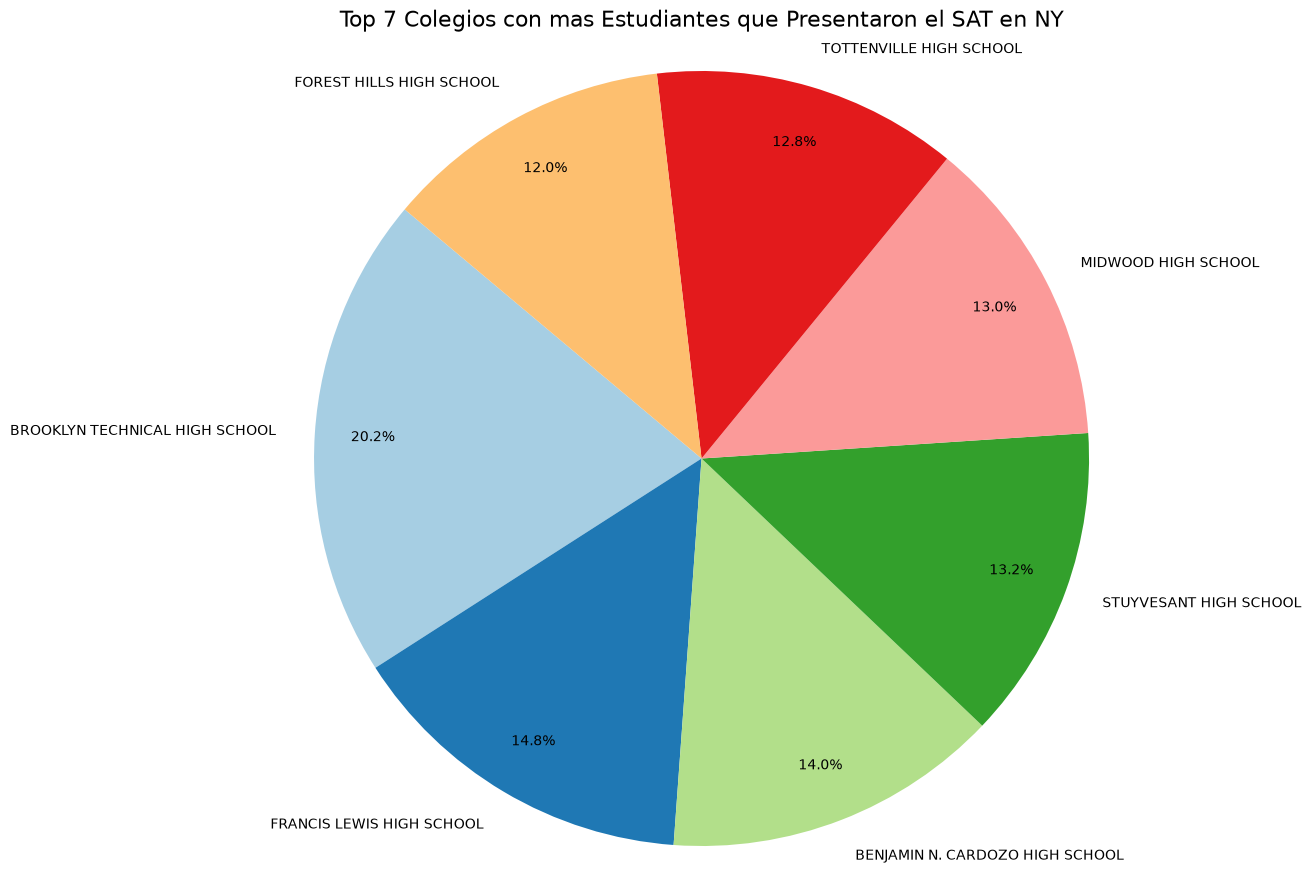

In [18]:
import matplotlib.pyplot as plt

colegios_spark = df03.filter(F.col("Examinados").isNotNull()).select("Colegio", "Examinados").orderBy("Examinados", ascending=False)

pd_colegios = colegios_spark.toPandas()

top_colegios = pd_colegios.head(7)


plt.figure(figsize=(11, 11))

plt.pie(
    top_colegios['Examinados'], 
    labels=top_colegios['Colegio'], 
    autopct='%1.1f%%', 
    startangle=140,

    pctdistance=0.85,
    colors=plt.cm.Paired.colors 
)

plt.title('Top 7 Colegios con mas Estudiantes que Presentaron el SAT en NY', fontsize=16)

plt.axis('equal') 

plt.show()

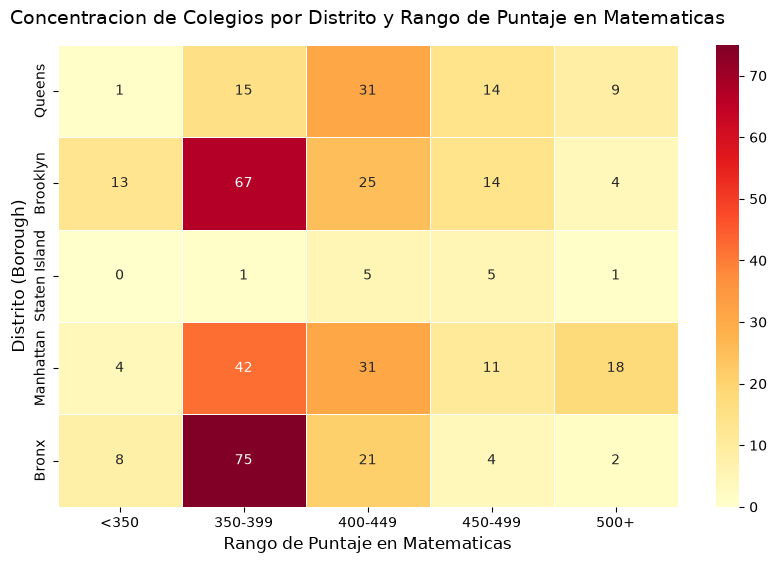

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

tabla_cruzada = dfRangos.stat.crosstab("Distrito", "RangoMatematicas")

pd_heatmap = tabla_cruzada.toPandas()

pd_heatmap = pd_heatmap.set_index('Distrito_RangoMatematicas')

columnas_ordenadas = ['<350', '350-399', '400-449', '450-499', '500+']
columnas_presentes = [col for col in columnas_ordenadas if col in pd_heatmap.columns]
pd_heatmap = pd_heatmap[columnas_presentes]

plt.figure(figsize=(10, 6))

sns.heatmap(pd_heatmap, annot=True, fmt='d', cmap='YlOrRd', linewidths=.5)

plt.title('Concentracion de Colegios por Distrito y Rango de Puntaje en Matematicas', fontsize=14, pad=15)
plt.xlabel('Rango de Puntaje en Matematicas', fontsize=12)
plt.ylabel('Distrito (Borough)', fontsize=12)

plt.show()

In [20]:
import os
from itertools import chain
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

CARPETA_SALIDA = "punto7_salida"          # aquí se guardan las tablas de resultado
os.makedirs(CARPETA_SALIDA, exist_ok=True)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

In [21]:
print("Columnas de df02:", df02.columns)
n0 = df02.count()
repetidos = n0 - df02.select("Dbn").distinct().count()
print(f"Filas (colegios): {n0:,}")
print(f"Codigos Dbn repetidos: {repetidos:,}")

Columnas de df02: ['Dbn', 'Colegio', 'Examinados', 'Lectura', 'Matematicas', 'Escritura', 'Distrito']


[Stage 65:==============>                                           (1 + 3) / 4]

Filas (colegios): 478
Codigos Dbn repetidos: 0


In [22]:
CENTINELAS = ["(NULL)", "NULL", "NAN", "NONE", "", "S"]     # la "s" es el valor suprimido de esta base

def resumen_faltantes(df):
    """Por columna: vacíos reales y textos 'sin dato' (incluida la 's'). Solo muestra las columnas que tienen algo."""
    exprs = []
    for c, t in df.dtypes:
        exprs.append(F.sum(F.col(c).isNull().cast("int")).alias(f"{c}|nulos"))
        if t == "string":
            exprs.append(F.sum(F.upper(F.trim(F.col(c))).isin(CENTINELAS).cast("int")).alias(f"{c}|textos_sin_dato"))
    fila = df.agg(*exprs).first().asDict()
    tabla = {}
    for k, v in fila.items():
        col, tipo = k.split("|")
        tabla.setdefault(col, {"nulos": 0, "textos_sin_dato": 0})[tipo] = int(v or 0)
    out = pd.DataFrame(tabla).T
    out["total"] = out.sum(axis=1)
    return out[out["total"] > 0].sort_values("total", ascending=False)

bitacora = []
def registrar(paso, antes, despues, afectadas=None):
    afectadas = (antes - despues) if afectadas is None else afectadas
    bitacora.append({"paso": paso, "filas_antes": antes, "filas_despues": despues, "afectadas": afectadas})
    print(f"{paso}\n   antes: {antes:,} | después: {despues:,} | afectadas: {afectadas:,}")

print("Faltantes en df02:")
resumen_faltantes(df02)

Faltantes en df02:


,nulos,textos_sin_dato,total
Examinados,0,57,57
Lectura,0,57,57
Matematicas,0,57,57
Escritura,0,57,57


In [23]:
def texto_a_nulo(df):
    """En las columnas de texto, '(null)', 'nan' y las cadenas vacías pasan a vacío real; se recortan los espacios."""
    for c, t in df.dtypes:
        if t == "string":
            limpio = F.trim(F.col(c))
            df = df.withColumn(c, F.when(F.upper(limpio).isin(*CENTINELAS), F.lit(None).cast("string")).otherwise(limpio))
    return df

base = texto_a_nulo(df03)
df05, filas = base, []
for c in ["Examinados", "Lectura", "Matematicas", "Escritura"]:
    con_s = df02.filter(F.upper(F.trim(F.col(c))) == "S").count()
    vacios = df05.filter(F.col(c).isNull()).count()
    filas.append({"columna": c, "valores_s": con_s, "vacios_despues": vacios, "ALERTA": vacios != con_s})
print(pd.DataFrame(filas).to_string(index=False))
df05 = df05.cache()
df05.printSchema()
df05.select("Dbn", "Colegio", "Distrito", "Examinados", "Lectura", "Matematicas", "Escritura").show(5)
df05.select(F.min("Examinados"), F.max("Examinados"), F.min("Lectura"), F.max("Lectura"),
            F.min("Matematicas"), F.max("Matematicas"), F.min("Escritura"), F.max("Escritura")).show()
print("Faltantes después del tipado:")
resumen_faltantes(df05)

    columna  valores_s  vacios_despues  ALERTA
 Examinados         57              57   False
    Lectura         57              57   False
Matematicas         57              57   False
  Escritura         57              57   False
root
 |-- Dbn: string (nullable = true)
 |-- Colegio: string (nullable = true)
 |-- Examinados: integer (nullable = true)
 |-- Lectura: integer (nullable = true)
 |-- Matematicas: integer (nullable = true)
 |-- Escritura: integer (nullable = true)
 |-- Distrito: string (nullable = true)



+------+--------------------+---------+----------+-------+-----------+---------+
|   Dbn|             Colegio| Distrito|Examinados|Lectura|Matematicas|Escritura|
+------+--------------------+---------+----------+-------+-----------+---------+
|01M292|HENRY STREET SCHO...|Manhattan|        29|    355|        404|      363|
|01M448|UNIVERSITY NEIGHB...|Manhattan|        91|    383|        423|      366|
|01M450|EAST SIDE COMMUNI...|Manhattan|        70|    377|        402|      370|
|01M458|FORSYTH SATELLITE...|Manhattan|         7|    414|        401|      359|
|01M509|MARTA VALLE HIGH ...|Manhattan|        44|    390|        433|      384|
+------+--------------------+---------+----------+-------+-----------+---------+
only showing top 5 rows
+---------------+---------------+------------+------------+----------------+----------------+--------------+--------------+
|min(Examinados)|max(Examinados)|min(Lectura)|max(Lectura)|min(Matematicas)|max(Matematicas)|min(Escritura)|max(Escritura)|

,nulos,textos_sin_dato,total
Examinados,57,0,57
Lectura,57,0,57
Matematicas,57,0,57
Escritura,57,0,57
